In [ ]:
from google.colab import userdata
GROQ_API_KEY = userdata.get('GROQ_API_KEY')

In [ ]:
# !pip install langchain_experimental langchain-groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 42.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.9 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
from groq import Groq
client = Groq(
    api_key = GROQ_API_KEY
)

models = client.models.list()
for model in models.data:
    print(model.id)

meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-v1-english
qwen/qwen3.8-27b
canopylabs/orpheus-arabic-saudi
openai/gpt-oss-20b
whisper-large-v3
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-120b
openai/gpt-oss-safeguard-20b
whisper-large-v3-turbo
allam-2-7b


In [ ]:
from langchain_experimental.graph_transformers import LLMGraphTransformer
from langchain_groq import ChatGroq

llm = ChatGroq(api_key=GROQ_API_KEY, model_name="qwen/qwen3.8-27b")
llm_transformer = LLMGraphTransformer(llm=llm)

In [ ]:
from langchain_core.documents import Document
from langchain_text_splitters import TokenTextSplitter

# Read the article
raw_text = """
Rahul works as an engineer at Nexa Energy in Mumbai, where the company develops battery energy storage systems for industrial customers. Rahul works closely with Priya, a software engineer responsible for developing the Energy Management System. The Energy Management System communicates with a Siemens PLC using Modbus TCP. The Siemens PLC collects operational measurements from a Battery Management System, which continuously monitors a battery manufactured by PowerCell Industries. Nexa Energy installed this battery system at GreenTech Factory in Pune. As part of the project, Rahul configured the Siemens PLC to communicate with the field equipment. Priya then connected the Energy Management System to the Siemens PLC for real-time monitoring. The Energy Management System receives battery measurements through the PLC and presents the information to the operators. Rahul and Priya tested the communication between the different systems. After successful testing, Nexa Energy deployed the complete energy management solution at GreenTech Factory.
"""

# Create LangChain Document
raw_documents = [Document(page_content=raw_text)]

# Create splitter
text_splitter = TokenTextSplitter(chunk_size=512, chunk_overlap=24)

documents = text_splitter.split_documents(raw_documents)

In [ ]:
# Extract graph data
graph_documents = llm_transformer.convert_to_graph_documents(documents)

In [ ]:
for graph_doc in graph_documents:
    print("\nNODES:")
    for node in graph_doc.nodes:
        print(node)

    print("\nRELATIONSHIPS:")
    for relationship in graph_doc.relationships:
        print(relationship)


NODES:
id='Rahul' type='Person' properties={}
id='Nexa Energy' type='Company' properties={}
id='Mumbai' type='Location' properties={}
id='Priya' type='Person' properties={}
id='Energy Management System' type='System' properties={}
id='Siemens Plc' type='Equipment' properties={}
id='Modbus Tcp' type='Protocol' properties={}
id='Battery Management System' type='System' properties={}
id='Battery' type='Product' properties={}
id='Powercell Industries' type='Company' properties={}
id='Greentech Factory' type='Location' properties={}
id='Pune' type='Location' properties={}

RELATIONSHIPS:
source=Node(id='Rahul', type='Person', properties={}) target=Node(id='Nexa Energy', type='Company', properties={}) type='WORKS_AT' properties={}
source=Node(id='Nexa Energy', type='Company', properties={}) target=Node(id='Mumbai', type='Location', properties={}) type='LOCATED_IN' properties={}
source=Node(id='Nexa Energy', type='Company', properties={}) target=Node(id='Battery', type='Product', properties=

In [ ]:
# !apt-get -qq install graphviz
# !pip install graphviz

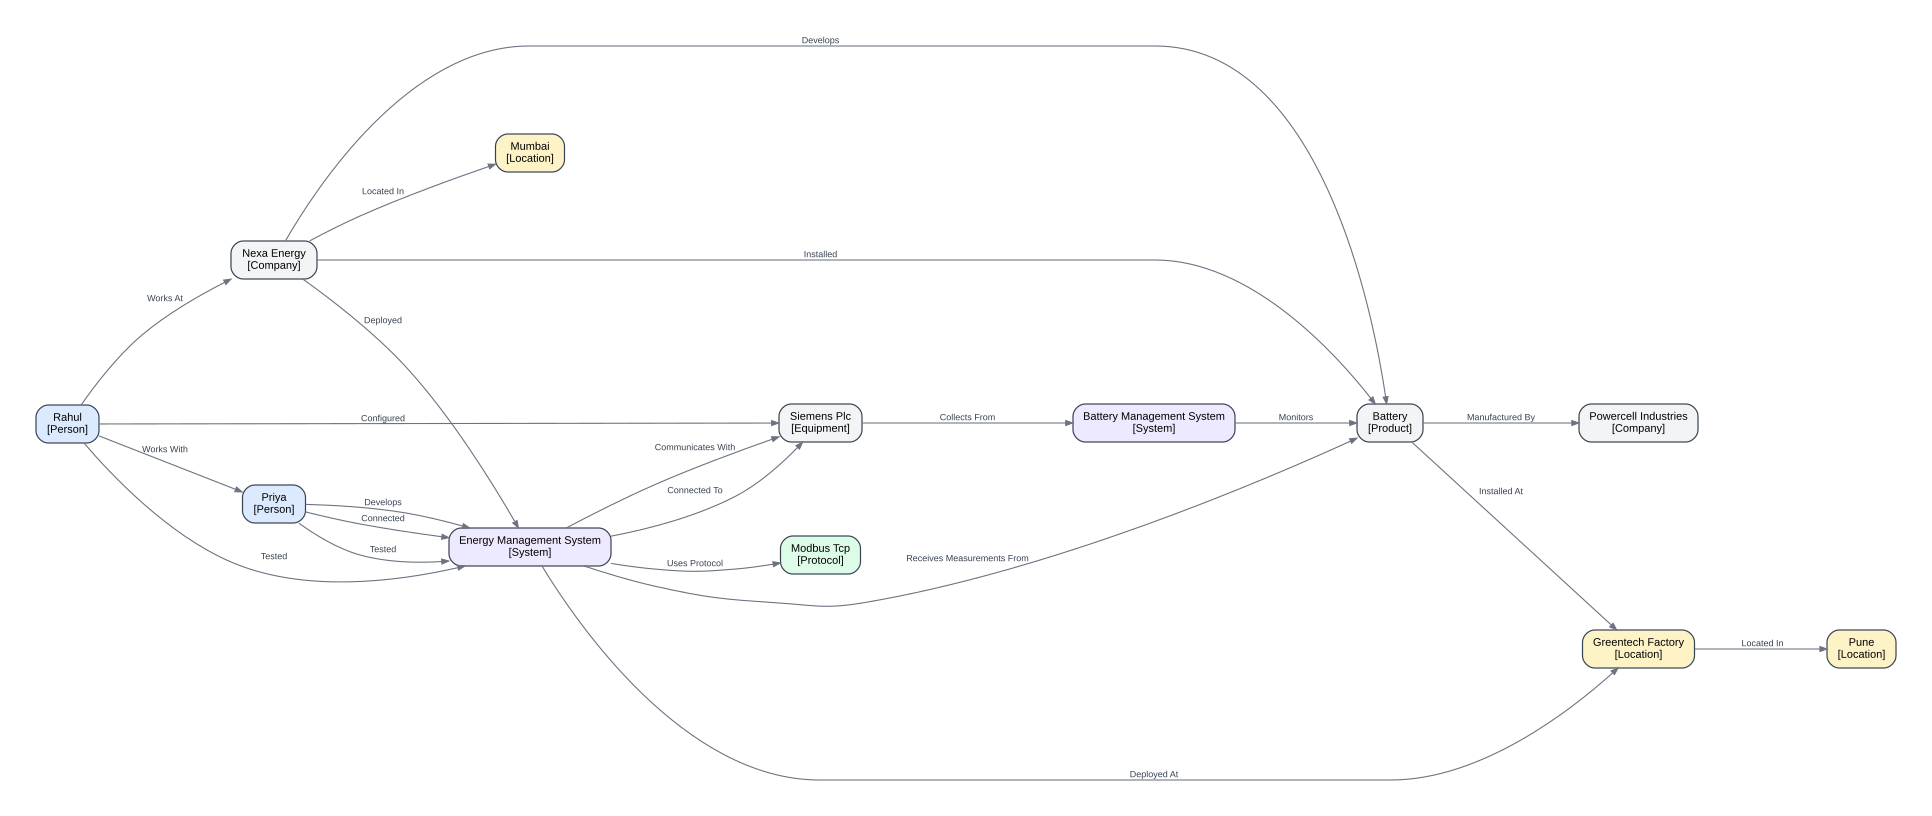

In [ ]:
from graphviz import Digraph
from IPython.display import display

dot = Digraph("KnowledgeGraph")

dot.attr(
    rankdir="LR",        # Left to Right
    bgcolor="white",
    pad="0.5",
    nodesep="0.8",
    ranksep="1.2",
    splines="spline"
)

# Global node style
dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="11",
    margin="0.15,0.10",
    color="#374151",
    penwidth="1.2"
)

# Global edge style
dot.attr(
    "edge",
    fontname="Arial",
    fontsize="9",
    color="#6B7280",
    fontcolor="#374151",
    arrowsize="0.7",
    penwidth="1.1"
)


# Colours based on entity type
color_map = {
    "Person": "#DBEAFE",
    "Organization": "#E5E7EB",
    "Organisation": "#E5E7EB",
    "Location": "#FEF3C7",
    "System": "#EDE9FE",
    "Device": "#FEE2E2",
    "Protocol": "#DCFCE7",
    "Unknown": "#F3F4F6"
}


# ----------------------------
# Add nodes
# ----------------------------

added_nodes = set()

for graph_doc in graph_documents:

    for node in graph_doc.nodes:

        if node.id not in added_nodes:

            node_type = node.type or "Unknown"

            colour = color_map.get(
                node_type,
                "#F3F4F6"
            )

            dot.node(
                str(node.id),
                label=f"{node.id}\n[{node_type}]",
                fillcolor=colour
            )

            added_nodes.add(node.id)


# ----------------------------
# Add relationships
# ----------------------------

for graph_doc in graph_documents:

    for rel in graph_doc.relationships:

        relationship = (
            rel.type
            .replace("_", " ")
            .title()
        )

        dot.edge(
            str(rel.source.id),
            str(rel.target.id),
            label=relationship
        )


# Display in Colab
display(dot)

## Extract unique node types

In [ ]:
node_types = set()

for graph_doc in graph_documents:
    for node in graph_doc.nodes:
        node_types.add(node.type)

print("NODE TYPES:")
for node_type in sorted(node_types):
    print(node_type)

NODE TYPES:
Company
Equipment
Location
Person
Product
Protocol
System


## Extract unique relationship types

In [ ]:
relationship_types = set()

for graph_doc in graph_documents:
    for relationship in graph_doc.relationships:
        relationship_types.add(relationship.type)

print("RELATIONSHIP TYPES:")
for relationship_type in sorted(relationship_types):
    print(relationship_type)

RELATIONSHIP TYPES:
COLLECTS_FROM
COMMUNICATES_WITH
CONFIGURED
CONNECTED
CONNECTED_TO
DEPLOYED
DEPLOYED_AT
DEVELOPS
INSTALLED
INSTALLED_AT
LOCATED_IN
MANUFACTURED_BY
MONITORS
RECEIVES_MEASUREMENTS_FROM
TESTED
USES_PROTOCOL
WORKS_AT
WORKS_WITH


In [ ]:
selected_node_types = [
    "System",
    "Device",
    "Protocol",
    "Location"
]

selected_relationship_types = [
    "COMMUNICATES_WITH",
    "USES_PROTOCOL",
    "COLLECTS_FROM",
    "MONITORS",
    "LOCATED_IN"
]

In [ ]:
from langchain_community.graphs.graph_document import GraphDocument

def filter_graph(graph_documents, selected_node_types, selected_relationship_types):
    filtered_graph_documents = []
    for graph_doc in graph_documents:
        # Filter nodes by type
        filtered_nodes = [
            node
            for node in graph_doc.nodes
            if node.type in selected_node_types
        ]
        # IDs of nodes remaining in graph
        selected_node_ids = {
            node.id
            for node in filtered_nodes
        }


        # Filter relationships
        filtered_relationships = [
            relationship
            for relationship in graph_doc.relationships

            if (
                relationship.type
                in selected_relationship_types

                and relationship.source.id
                in selected_node_ids

                and relationship.target.id
                in selected_node_ids
            )
        ]

        # Create new filtered GraphDocument
        filtered_graph = GraphDocument(
            nodes=filtered_nodes,
            relationships=filtered_relationships,
            source=graph_doc.source
        )

        filtered_graph_documents.append(
            filtered_graph
        )
    return filtered_graph_documents

In [ ]:
filtered_graph_documents = filter_graph(
    graph_documents,
    selected_node_types,
    selected_relationship_types
)

In [ ]:
for graph_doc in filtered_graph_documents:
    print("\n========== NODES ==========")
    for node in graph_doc.nodes:
        print(f"{node.id} [{node.type}]")

    print("\n========== RELATIONSHIPS ==========")
    for relationship in graph_doc.relationships:
        print(
            f"{relationship.source.id} "
            f"--[{relationship.type}]--> "
            f"{relationship.target.id}"
        )


========== NODES ==========
Mumbai [Location]
Energy Management System [System]
Modbus Tcp [Protocol]
Battery Management System [System]
Greentech Factory [Location]
Pune [Location]

========== RELATIONSHIPS ==========
Energy Management System --[USES_PROTOCOL]--> Modbus Tcp
Greentech Factory --[LOCATED_IN]--> Pune


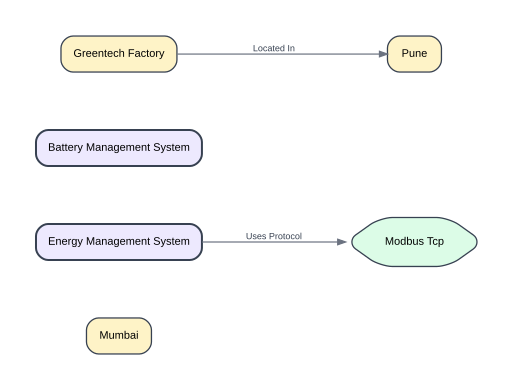

In [ ]:
from graphviz import Digraph
from IPython.display import SVG, display

# CREATE FILTERED GRAPHVIZ GRAPH
dot_filtered = Digraph(
    name="FilteredKnowledgeGraph",
    format="svg"
)

# GRAPH SETTINGS
dot_filtered.attr(
    rankdir="LR",
    bgcolor="white",
    pad="0.5",
    nodesep="0.8",
    ranksep="1.2",
    splines="spline"
)

# DEFAULT NODE SETTINGS
dot_filtered.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="11",
    margin="0.18,0.12",
    color="#374151",
    penwidth="1.4"
)

# DEFAULT EDGE SETTINGS
dot_filtered.attr(
    "edge",
    fontname="Arial",
    fontsize="9",
    color="#6B7280",
    fontcolor="#374151",
    arrowsize="0.8",
    penwidth="1.2"
)

# NODE COLOURS
color_map = {
    "Person": "#DBEAFE",
    "Organization": "#E5E7EB",
    "Organisation": "#E5E7EB",
    "Location": "#FEF3C7",
    "System": "#EDE9FE",
    "Device": "#FEE2E2",
    "Protocol": "#DCFCE7",
    "Equipment": "#FCE7F3",
    "Component": "#E0F2FE",
    "Unknown": "#F3F4F6"
}

# NODE SHAPES
shape_map = {
    "Person": "ellipse",
    "Organization": "box",
    "Organisation": "box",
    "Location": "box",
    "System": "box",
    "Device": "box",
    "Protocol": "hexagon",
    "Equipment": "box",
    "Component": "box",
    "Unknown": "box"
}

# ADD FILTERED NODES
added_nodes = set()
for graph_doc in filtered_graph_documents:
    for node in graph_doc.nodes:
        node_id = str(node.id)
        node_type = (
            node.type
            if node.type
            else "Unknown"
        )

        if node_id not in added_nodes:
            node_color = color_map.get(
                node_type,
                "#F3F4F6"
            )

            node_shape = shape_map.get(
                node_type,
                "box"
            )

            # Highlight system nodes
            if node_type == "System":
                penwidth = "2.0"
            else:
                penwidth = "1.3"

            dot_filtered.node(
                name=node_id,
                label=node_id,
                fillcolor=node_color,
                shape=node_shape,
                penwidth=penwidth,
                tooltip=(
                    f"{node_id} | "
                    f"Type: {node_type}"
                )
            )

            added_nodes.add(
                node_id
            )

# ADD FILTERED RELATIONSHIPS
added_edges = set()
for graph_doc in filtered_graph_documents:
    for relationship in graph_doc.relationships:
        source = str(
            relationship.source.id
        )
        target = str(
            relationship.target.id
        )
        relationship_type = str(
            relationship.type
        )
        edge_key = (
            source,
            target,
            relationship_type
        )
        if edge_key not in added_edges:
            edge_label = (
                relationship_type
                .replace("_", " ")
                .title()
            )
            dot_filtered.edge(
                source,
                target,
                label=edge_label,
                tooltip=relationship_type
            )
            added_edges.add(
                edge_key
            )

# GENERATE SVG
svg_data = dot_filtered.pipe(
    format="svg"
)

# DISPLAY SVG
display(
    SVG(svg_data)
)

In [ ]:
# !pip install -q neo4j

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 390.6/390.6 kB 7.7 MB/s eta 0:00:00


In [ ]:
from neo4j import GraphDatabase

NEO4J_URI = userdata.get("NEO4J_URI")
NEO4J_USERNAME = userdata.get("NEO4J_USERNAME")
NEO4J_PASSWORD = userdata.get("NEO4J_PASSWORD")
NEO4J_DATABASE = userdata.get("NEO4J_DATABASE") or "neo4j"

if not NEO4J_URI:
    raise ValueError("NEO4J_URI was not found in Colab Secrets.")
if not NEO4J_USERNAME:
    raise ValueError("NEO4J_USERNAME was not found in Colab Secrets.")
if not NEO4J_PASSWORD:
    raise ValueError("NEO4J_PASSWORD was not found in Colab Secrets.")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(
        NEO4J_USERNAME,
        NEO4J_PASSWORD
    )
)
driver.verify_connectivity()
print("Successfully connected to Neo4j.")

In [ ]:
graph = Neo4jGraph(url=NE04J_URI, username=NE04J_USERNAME, password=NE04J_PASSWORD)
graph.add_graph_documents(graph_documents)